In [140]:
import numpy as np
import pandas as pd

In [141]:
data=pd.read_csv('data (1).csv')

In [142]:
data.head()

,Var_X,Var_Y
0,-0.33532,6.66854
1,0.02160,3.86398
2,-1.19438,5.16161
3,-0.65046,8.43823
4,-0.28001,5.57201


In [143]:
X=np.array(data['Var_X']).reshape(-1,1)

In [144]:
X

array([[-0.33532],
       [ 0.0216 ],
       [-1.19438],
       [-0.65046],
       [-0.28001],
       [ 1.93258],
       [ 1.2262 ],
       [ 0.74727],
       [ 3.32853],
       [ 2.87457],
       [-1.48662],
       [ 0.37629],
       [ 1.43918],
       [ 0.24183],
       [-2.7914 ],
       [ 1.08176],
       [ 2.81555],
       [ 0.54924],
       [ 2.36449],
       [-1.01925]])

In [145]:
y=data['Var_Y']

In [146]:
from sklearn.preprocessing import PolynomialFeatures

In [147]:
poly_feat=PolynomialFeatures(degree=6)
X_poly=poly_feat.fit_transform(X)

In [148]:
X_poly

array([[ 1.00000000e+00, -3.35320000e-01,  1.12439502e-01,
        -3.77032139e-02,  1.26426417e-02, -4.23933061e-03,
         1.42153234e-03],
       [ 1.00000000e+00,  2.16000000e-02,  4.66560000e-04,
         1.00776960e-05,  2.17678234e-07,  4.70184985e-09,
         1.01559957e-10],
       [ 1.00000000e+00, -1.19438000e+00,  1.42654358e+00,
        -1.70383513e+00,  2.03502660e+00, -2.43059507e+00,
         2.90305414e+00],
       [ 1.00000000e+00, -6.50460000e-01,  4.23098212e-01,
        -2.75208463e-01,  1.79012097e-01, -1.16440208e-01,
         7.57396980e-02],
       [ 1.00000000e+00, -2.80010000e-01,  7.84056001e-02,
        -2.19543521e-02,  6.14743813e-03, -1.72134415e-03,
         4.81993575e-04],
       [ 1.00000000e+00,  1.93258000e+00,  3.73486546e+00,
         7.21792628e+00,  1.39492200e+01,  2.69579835e+01,
         5.20984598e+01],
       [ 1.00000000e+00,  1.22620000e+00,  1.50356644e+00,
         1.84367317e+00,  2.26071204e+00,  2.77208510e+00,
         3.3991307

In [149]:
from sklearn.linear_model import LinearRegression

In [150]:
lr=LinearRegression()

In [151]:
lr.fit(X_poly,y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](7,)","[ 0. ,-7.27,-2.86,..., 0.2 ,-0.08, 0.01]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,3.726
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,7
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(6)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](7,)","[1535.53, 298.18, 28.39,..., 1.96, 1.03, 0. ]"


In [152]:
print(f'Polynomial_coefficient:{lr.coef_}')
print(f'Intercept:{lr.intercept_}')

Polynomial_coefficient:[ 0.         -7.2669612  -2.86035154  1.28291345  0.20121229 -0.07667821
  0.01121114]
Intercept:3.7256417114296365


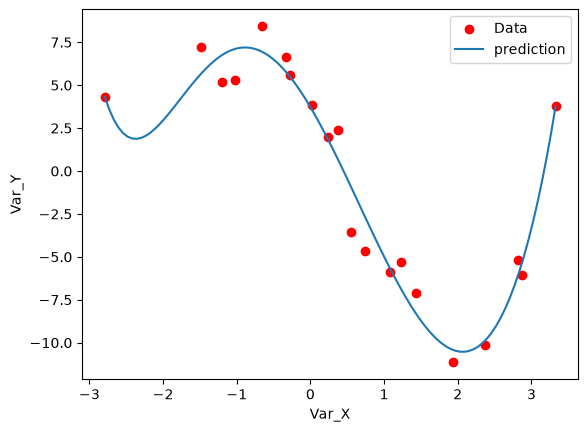

In [153]:
X_new=np.linspace(data['Var_X'].min(),data['Var_X'].max(),100).reshape(100,1)
X_new_poly=poly_feat.transform(X_new)
y_new=lr.predict(X_new_poly)
plt.scatter(X,y,color='red',label="Data")
plt.plot(X_new,y_new,label='prediction')
plt.xlabel("Var_X")
plt.ylabel("Var_Y")
plt.legend()
plt.show()